# 3.1 시장 단독 회귀와 시장·순섹터 회귀 비교

**목적:** 순섹터 요인을 추가했을 때 일별 회귀 잔차와 경보가 어떻게 달라지는지 확인한다.
- **A — 시장 단독:** 종목 수익률 = 절편 + 시장 설명분 + 잔차.
- **B — 시장·순섹터:** 현재 프로젝트의 `detect()`를 그대로 실행한다.
- 기존 `run_config.json`의 분석 기간·설정·입력 파일 해시를 확인한다. 첨부본 기준 분석 기간은 **2025-01-02~2026-10-08**이며 2024년 준비 자료도 계산에 사용한다.
- 120거래일 회귀, 40거래일 Z, 표본 표준편차, 가격·거래량 2.5, 입력 품질 규칙을 유지한다. 당일·미래 자료는 회귀 추정 및 Z 기준 창에 넣지 않는다.
- 당일 시장·업종 수익률로 장 마감 후 기대 수익률을 계산한다. **다음 날 수익률 예측 실험이 아니다.**
- 시장 단독 모델도 모든 거래일을 먼저 계산한다. 지표는 **두 모델 모두 판정 가능한 동일 종목·날짜**에서 비교한다.

**실행:** 이 파일을 `FDS_regression_model` 폴더 또는 그 안의 `experiments` 폴더에 두고, 기존 `aicam` 커널에서 위부터 실행한다. 다른 위치에서 실행하면 코드 셀 1의 `MODEL_DIR`만 지정한다. `numpy`, `pandas`, `matplotlib`, `IPython`이 필요하다.

**보고서:** 코드 셀 **1(조건), 3(표본), 4(핵심 지표), 5(변경 사례), 6(그림), 7(수치 요약·저장)**을 확인한다. 코드 셀 2는 계산용이다. 표·그림은 마지막 셀에서 별도 폴더에 저장한다.

## 코드 셀 1 · 기존 실행 조건 확인
입력과 실행 기록이 다르면 중단한다. 의도적으로 데이터를 갱신한 경우에는 기존 모델을 먼저 실행하여 `run_config.json`을 갱신한 뒤 이 노트북을 실행한다. 운영 결과 파일은 수정하지 않는다.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

MODEL_DIR = None  # 필요할 때만 Path(r"C:\ai_campus_mini_proj\FDS_regression_model")로 변경
if MODEL_DIR is None:
    candidates = [p / name for p in [Path.cwd(), *Path.cwd().parents]
                  for name in ("", "FDS_regression_model")]
    MODEL_DIR = next((p for p in candidates if (p / "semiconductor_model/core.py").is_file()), None)
if MODEL_DIR is None:
    raise FileNotFoundError("MODEL_DIR에 FDS_regression_model 폴더 경로를 지정하세요.")
MODEL_DIR = Path(MODEL_DIR).resolve()
sys.path.insert(0, str(MODEL_DIR))
from semiconductor_model import core
from semiconductor_model.config import CONFIG
from semiconductor_model.data import read_inputs, build_panel, exceeds_return_limit
assert Path(core.__file__).resolve().parents[1] == MODEL_DIR, "커널을 재시작하고 다시 실행하세요."

run = json.loads((MODEL_DIR / "run_config.json").read_text(encoding="utf-8"))
assert CONFIG.to_dict() == run["model"], "현재 코드와 실행 설정이 다릅니다. 기존 모델을 먼저 실행하세요."
START, END = pd.Timestamp(run["analysis_start"]), pd.Timestamp(run["analysis_end"])
DATA = MODEL_DIR / "data"
sha256 = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes = {n: sha256(DATA / n) for n in ("stocks.csv", "markets.csv", "calendar.csv", "universe.csv")}
assert input_hashes == run["inputs"]["sha256"], "입력 파일이 기존 실행과 다릅니다. 경로 또는 실행 기록을 확인하세요."
stocks, markets, calendar, universe = read_inputs(DATA, END)
panel = build_panel(stocks, markets, calendar, universe, CONFIG)
OUT = MODEL_DIR / "experiments" / "3_1_market_vs_market_sector"
display(pd.DataFrame({"항목": ["분석 기간", "준비 자료 포함 입력 기간", "분석 대상", "회귀 / Z 구간", "가격 / 거래량 임계값", "입력·설정 검증"],
    "값": [f"{START.date()} ~ {END.date()}", f"{calendar.date.min().date()} ~ {calendar.date.max().date()}",
           f"{panel.code.nunique()}개사", f"직전 {CONFIG.train_window} / {CONFIG.z_window}거래일 (당일 제외)",
           f"|가격 Z| ≥ {CONFIG.price_threshold} / 거래량 Z ≥ {CONFIG.volume_threshold}", "기존 실행 기록과 일치"]}))

,항목,값
0,분석 기간,2025-01-02 ~ 2026-10-08
1,준비 자료 포함 입력 기간,2024-01-02 ~ 2026-10-08
2,분석 대상,6개사
3,회귀 / Z 구간,직전 120 / 40거래일 (당일 제외)
4,가격 / 거래량 임계값,|가격 Z| ≥ 2.5 / 거래량 Z ≥ 2.5
5,입력·설정 검증,기존 실행 기록과 일치


## 코드 셀 2 · 두 모델 계산
시장 단독 모델은 기존 OLS 함수와 입력 규칙을 사용한다. 거래량 Z와 시장 보조 정보는 기존 계산값을 재사용한다. 가격 Z는 각 모델에서 날짜별로 생성한 과거 잔차로 따로 계산한다. 섹터를 상수 0으로 바꾸어 기존 2변수 회귀에 넣는 방식은 사용하지 않는다.

In [2]:
def market_only(panel, full, cfg=CONFIG):
    parts = []
    for stock_code, group in panel.groupby("code", sort=True):
        g = group.sort_values("date").reset_index(drop=True)
        b = full.loc[full.code.eq(stock_code)].sort_values("date").reset_index(drop=True)
        assert g.date.equals(b.date)
        status_in = g.input_status.astype(str).copy()
        excessive = exceeds_return_limit(g.stock_return, cfg)
        status_in.loc[~np.isfinite(g.volume) | g.volume.le(0)] = "MISSING_OR_ZERO_VOLUME"
        status_in.loc[excessive] = "RETURN_EXCEEDS_30PCT"
        r = g.stock_return.mask(excessive).where(status_in.eq("OK"))
        values = np.column_stack([r, g.market_return])
        expected = np.full(len(g), np.nan)
        status = pd.Series("INSUFFICIENT_REGRESSION_HISTORY", index=g.index)
        for t in range(cfg.train_window, len(g)):
            train, today = values[t-cfg.train_window:t], values[t]
            if not np.isfinite(today).all():
                status.iloc[t] = "MISSING_CURRENT_INPUT"
                continue
            if not np.isfinite(train).all():
                status.iloc[t] = "INCOMPLETE_REGRESSION_WINDOW"
                continue
            fit = core._ols(train[:, [1]], train[:, 0], cfg.scale_floor)
            if fit is None:
                status.iloc[t] = "RANK_DEFICIENT_REGRESSION"
                continue
            expected[t] = fit[0] + fit[1][0] * today[1]
            status.iloc[t] = "OK"
        residual = g.stock_return - expected
        ref = residual.shift(1).rolling(cfg.z_window, min_periods=cfg.z_window)
        scale = ref.std(ddof=cfg.std_ddof)
        price_z = (residual - ref.mean()) / scale.where(scale > cfg.scale_floor)
        status.loc[status.eq("OK") & ~np.isfinite(price_z)] = "INCOMPLETE_PRICE_Z_WINDOW"
        status.loc[scale.le(cfg.scale_floor) & residual.notna()] = "ZERO_PRICE_SCALE"
        status.loc[status.eq("OK") & ~np.isfinite(b.volume_z)] = "INCOMPLETE_VOLUME_Z_WINDOW"
        usable = np.isfinite(g.volume) & g.volume.gt(0) & ~excessive & g.usable_quote
        usable &= status_in.isin(["OK", "MISSING_PREVIOUS_QUOTE"])
        vref = np.log1p(g.volume.where(usable)).shift(1).rolling(cfg.z_window, min_periods=cfg.z_window)
        status.loc[status.eq("INCOMPLETE_VOLUME_Z_WINDOW") & vref.std(ddof=cfg.std_ddof).le(cfg.scale_floor)] = "ZERO_VOLUME_SCALE"
        status.loc[~status_in.eq("OK")] = status_in.loc[~status_in.eq("OK")]
        valid = status.eq("OK") & np.isfinite(price_z) & np.isfinite(b.volume_z)
        a = b[["date", "code", "name", "stock_return", "volume_z"]].copy()
        a["expected_return"], a["price_residual"], a["price_z"] = expected, residual, price_z
        a["decision_status"] = status
        a["price_alert"] = pd.Series(pd.NA, index=a.index, dtype="boolean")
        a["volume_alert"] = pd.Series(pd.NA, index=a.index, dtype="boolean")
        a.loc[valid, "price_alert"] = price_z.loc[valid].abs().ge(cfg.price_threshold)
        a.loc[valid, "volume_alert"] = b.loc[valid, "volume_z"].ge(cfg.volume_threshold)
        a["alert_type"] = pd.Series(pd.NA, index=a.index, dtype="string")
        p = a.loc[valid, "price_alert"].to_numpy(dtype=bool)
        v = a.loc[valid, "volume_alert"].to_numpy(dtype=bool)
        a.loc[valid, "alert_type"] = np.select([p & v, p, v],
            ["PRICE_AND_VOLUME", "PRICE_ONLY", "VOLUME_ONLY"], default="NO_ALERT")
        parts.append(a)
    return pd.concat(parts, ignore_index=True).sort_values(["date", "code"]).reset_index(drop=True)

sector_all = core.detect(panel, CONFIG)
market_all = market_only(panel, sector_all)
trim = lambda df: df.loc[df.date.between(START, END)].reset_index(drop=True)
market, sector = trim(market_all), trim(sector_all)
assert len(sector) == run["rows"], "기존 실행의 결과 행 수와 다릅니다."
assert int((sector.price_alert | sector.volume_alert).sum()) == run["stock_alert_json_count"], "기존 실행의 경보 수와 다릅니다."
print("계산 완료 · 기존 시장·순섹터 모델의 결과 행 수와 경보 수 재현 확인")

계산 완료 · 기존 시장·순섹터 모델의 결과 행 수와 경보 수 재현 확인


## 코드 셀 3 · 공통 비교 표본 확인 [보고서: 실험 조건]
`공통 비교`가 지표의 분모다. `비교 제외`에는 어느 한 모델이라도 판정 불가인 행이 들어간다. 계산 전에 결측 행을 삭제하거나 거래일 창을 압축하지 않는다. 관측 단위는 **종목×거래일**이다.

In [3]:
keys = ["date", "code", "name"]
cols = keys + ["stock_return", "expected_return", "price_residual", "price_z", "volume_z",
               "price_alert", "volume_alert", "alert_type", "decision_status"]
joined = market[cols].merge(sector[cols + ["sector_part"]], on=keys,
                            suffixes=("_m", "_s"), validate="one_to_one")
np.testing.assert_allclose(joined.volume_z_m, joined.volume_z_s, equal_nan=True)
joined["valid_m"] = joined.decision_status_m.eq("OK")
joined["valid_s"] = joined.decision_status_s.eq("OK")
joined["common"] = joined.valid_m & joined.valid_s
coverage = joined.groupby(["code", "name"], sort=True).agg(
    total=("date", "size"), market_valid=("valid_m", "sum"), sector_valid=("valid_s", "sum"), common=("common", "sum"))
coverage["excluded"] = coverage.total - coverage.common
coverage = coverage.reset_index()
coverage.loc[len(coverage)] = ["ALL", "전체", *coverage.iloc[:, 2:].sum().tolist()]
pair = joined.loc[joined.common].copy()
assert not pair.empty, "공통 비교 표본이 없습니다. 입력 자료를 확인하세요."
assert set(pair.code) == set(sector.code), "공통 비교 표본이 없는 기업이 있습니다."
for suffix in ("m", "s"):
    pair[f"or_{suffix}"] = pair[f"price_alert_{suffix}"].astype(bool) | pair[f"volume_alert_{suffix}"].astype(bool)
coverage_table = coverage.rename(columns={"code": "종목코드", "name": "기업", "total": "분석 행",
    "market_valid": "시장 단독 유효", "sector_valid": "시장·순섹터 유효", "common": "공통 비교", "excluded": "비교 제외"})
display(coverage_table)
print(f"공통 표본의 날짜 범위: {pair.date.min().date()} ~ {pair.date.max().date()} / {len(pair):,}개 종목·거래일")

,종목코드,기업,분석 행,시장 단독 유효,시장·순섹터 유효,공통 비교,비교 제외
0,000660,SK하이닉스,429,429,429,429,0
1,000990,DB하이텍,429,429,429,429,0
2,005930,삼성전자,429,429,429,429,0
3,036930,주성엔지니어링,429,429,429,429,0
4,042700,한미반도체,429,429,429,429,0
5,240810,원익IPS,429,429,429,429,0
6,ALL,전체,2574,2574,2574,2574,0


공통 표본의 날짜 범위: 2025-01-02 ~ 2026-10-08 / 2,574개 종목·거래일


## 코드 셀 4 · 전체·기업별 비교표 [보고서: 핵심 결과]
**RMSE·MAE**는 과거 120일로 추정한 회귀식에 당일 설명변수를 넣어 얻은 잔차의 크기다. 낮을수록 공통 움직임으로 설명되지 않은 수익률이 작다. 단위는 **%p**이며 `RMSE 감소율 = (시장 단독 RMSE − 시장·순섹터 RMSE) / 시장 단독 RMSE × 100`이다. 양수이면 감소, 음수이면 증가다. 전체 RMSE는 공통 관측을 합쳐 계산하며 기업별 RMSE의 단순평균이 아니다.

가격 경보는 섹터 추가 효과를 직접 보여 주고, 최종 OR 경보는 서비스 출력의 변화를 보여 준다. **잔차 감소나 경보 감소만으로 이상 탐지 정확도가 높아졌다고 해석하지 않는다.**

In [4]:
rmse = lambda x: float(np.sqrt(np.mean(np.square(x))))
def metric_row(g, suffix, label):
    e = g[f"price_residual_{suffix}"]
    return {"모델": label, "공통 관측 수": len(g), "RMSE(%p)": 100 * rmse(e),
            "MAE(%p)": 100 * e.abs().mean(), "가격 경보(건)": int(g[f"price_alert_{suffix}"].sum()),
            "최종 OR(건)": int(g[f"or_{suffix}"].sum()), "최종 OR 비율(%)": 100 * g[f"or_{suffix}"].mean()}
summary = pd.DataFrame([metric_row(pair, "m", "시장 단독"), metric_row(pair, "s", "시장·순섹터")])
rows = []
for (stock_code, name), g in pair.groupby(["code", "name"], sort=True):
    m, s = rmse(g.price_residual_m), rmse(g.price_residual_s)
    rows.append({"종목코드": stock_code, "기업": name, "관측 수": len(g),
        "시장 RMSE(%p)": 100*m, "시장·순섹터 RMSE(%p)": 100*s,
        "RMSE 감소율(%)": 100*(m-s)/m if m > 0 else np.nan,
        "시장 가격 경보": int(g.price_alert_m.sum()), "시장·순섹터 가격 경보": int(g.price_alert_s.sum()),
        "시장 OR": int(g.or_m.sum()), "시장·순섹터 OR": int(g.or_s.sum())})
by_company = pd.DataFrame(rows)
display(summary.round(4))
display(by_company.round(4))

,모델,공통 관측 수,RMSE(%p),MAE(%p),가격 경보(건),최종 OR(건),최종 OR 비율(%)
0,시장 단독,2574,3.8074,2.4563,93,133,5.1671
1,시장·순섹터,2574,3.4415,2.1743,94,138,5.3613


,종목코드,기업,관측 수,시장 RMSE(%p),시장·순섹터 RMSE(%p),RMSE 감소율(%),시장 가격 경보,시장·순섹터 가격 경보,시장 OR,시장·순섹터 OR
0,000660,SK하이닉스,429,2.2961,2.2947,0.0583,8,8,12,14
1,000990,DB하이텍,429,3.8760,3.4915,9.9186,19,19,25,26
2,005930,삼성전자,429,1.6163,1.5829,2.0652,16,16,24,24
3,036930,주성엔지니어링,429,4.9546,4.6602,5.9408,14,17,22,24
4,042700,한미반도체,429,4.2722,3.9414,7.7419,23,20,30,30
5,240810,원익IPS,429,4.6118,3.7215,19.3051,13,14,20,20


## 코드 셀 5 · 경보 추가·해제와 변경 사례 [보고서: 해석 근거]
‘추가’는 A에서 미경보 → B에서 경보, ‘해제’는 A에서 경보 → B에서 미경보다. 이 표현은 정탐·오탐 판정을 뜻하지 않는다. 표에는 **가격 Z 변화의 절댓값이 큰 변경 사례 최대 10건**만 표시하고, 저장 파일에는 모든 변경 사례를 남긴다. 순섹터 설명분은 `섹터 베타 × 당일 순섹터 수익률`이다.

In [5]:
transitions = []
for label, cm, cs in [("가격 경보", "price_alert_m", "price_alert_s"), ("최종 OR", "or_m", "or_s")]:
    m, s = pair[cm].astype(bool), pair[cs].astype(bool)
    transitions.append({"구분": label, "공통 경보": int((m & s).sum()), "추가": int((~m & s).sum()),
                        "해제": int((m & ~s).sum()), "공통 미경보": int((~m & ~s).sum())})
transition_table = pd.DataFrame(transitions)
changed = pair.loc[pair.alert_type_m.ne(pair.alert_type_s)].copy()
changed["z_change"] = (changed.price_z_s - changed.price_z_m).abs()
changed = changed.sort_values(["z_change", "date", "code"], ascending=[False, True, True])
cases = pd.DataFrame({"날짜": changed.date.dt.strftime("%Y-%m-%d"), "종목코드": changed.code, "기업": changed.name,
    "실제 수익률(%)": 100*changed.stock_return_m, "시장 가격 Z": changed.price_z_m,
    "시장·순섹터 가격 Z": changed.price_z_s, "순섹터 설명분(%p)": 100*changed.sector_part,
    "거래량 Z": changed.volume_z_m, "시장 경보 유형": changed.alert_type_m, "시장·순섹터 경보 유형": changed.alert_type_s})
display(transition_table)
display(cases.head(10).round(4))

,구분,공통 경보,추가,해제,공통 미경보
0,가격 경보,77,17,16,2464
1,최종 OR,123,15,10,2426


,날짜,종목코드,기업,실제 수익률(%),시장 가격 Z,시장·순섹터 가격 Z,순섹터 설명분(%p),거래량 Z,시장 경보 유형,시장·순섹터 경보 유형
2449,2026-09-07,000990,DB하이텍,12.1246,2.4618,4.3702,-1.1609,1.8532,NO_ALERT,PRICE_ONLY
2062,2026-06-04,042700,한미반도체,10.3448,2.6796,1.4329,6.5619,1.5351,PRICE_ONLY,NO_ALERT
1561,2026-01-28,000990,DB하이텍,9.5188,2.8872,1.7511,2.7462,1.7977,PRICE_ONLY,NO_ALERT
1113,2025-10-10,036930,주성엔지니어링,4.8309,2.5152,1.4217,2.6071,1.5895,PRICE_ONLY,NO_ALERT
1436,2025-12-26,005930,삼성전자,5.3105,2.9060,1.8386,1.2246,1.4297,PRICE_ONLY,NO_ALERT
1454,2026-01-02,005930,삼성전자,7.1726,2.6556,1.6383,1.5013,1.4018,PRICE_ONLY,NO_ALERT
1593,2026-02-04,036930,주성엔지니어링,6.9042,1.5438,2.5130,-1.8833,1.1988,NO_ALERT,PRICE_ONLY
2021,2026-05-22,240810,원익IPS,-2.8731,-2.9366,-2.0019,-3.2548,-0.3391,PRICE_ONLY,NO_ALERT
1102,2025-10-01,042700,한미반도체,-1.6580,-1.7658,-2.6863,2.0199,0.9856,NO_ALERT,PRICE_ONLY
720,2025-07-03,000660,SK하이닉스,-0.1792,-1.6853,-2.5761,1.1233,0.1955,NO_ALERT,PRICE_ONLY


## 코드 셀 6 · 보고서 첨부용 그림
왼쪽은 기업별 잔차 RMSE, 오른쪽은 가격 경보 수다. 거래량 경보 조건은 동일하다. 그림의 종목코드는 코드 셀 4의 기업명과 대응한다. 마지막 셀에서 300dpi PNG로 저장한다.

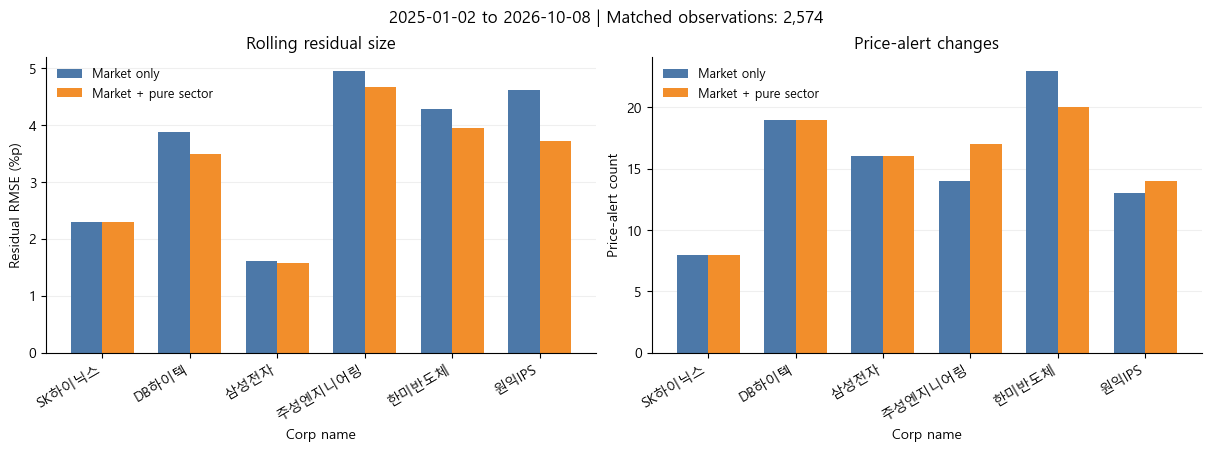

In [6]:
# 한글 기업명을 표시할 수 있는 폰트를 그래프 생성 전에 설정한다.
from matplotlib import font_manager
from pathlib import Path

# Windows의 맑은 고딕을 등록해 오래된 Matplotlib 폰트 캐시에도 대응한다.
malgun_path = Path("C:/Windows/Fonts/malgun.ttf")
if malgun_path.is_file():
    font_manager.fontManager.addfont(str(malgun_path))
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
korean_font = next((name for name in (
    "Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR"
) if name in available_fonts), None)
if korean_font is None:
    raise RuntimeError("한글 폰트가 없습니다. 맑은 고딕·나눔고딕·Noto Sans KR 중 하나를 설치한 뒤 커널을 재시작하세요.")
plt.rcParams["font.family"] = korean_font
plt.rcParams["axes.unicode_minus"] = False

x = np.arange(len(by_company))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for ax, left, right, ylabel, title in [
    (axes[0], "시장 RMSE(%p)", "시장·순섹터 RMSE(%p)", "Residual RMSE (%p)", "Rolling residual size"),
    (axes[1], "시장 가격 경보", "시장·순섹터 가격 경보", "Price-alert count", "Price-alert changes")]:
    ax.bar(x - 0.18, by_company[left], 0.36, label="Market only", color="#4C78A8")
    ax.bar(x + 0.18, by_company[right], 0.36, label="Market + pure sector", color="#F28E2B")
    ax.set_xticks(x, by_company["기업"], rotation=30, ha="right")
    ax.set(ylabel=ylabel, title=title, xlabel="Corp name")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
fig.suptitle(f"{START.date()} to {END.date()} | Matched observations: {len(pair):,}", fontsize=12)
plt.show()

## 코드 셀 7 · 수치 요약 및 출력물 저장 [보고서 작성 시 확인]
비교표 5개(CSV), 그림(PNG), 실험 기록(JSON)을 저장한다. CSV는 계산 정밀도를 유지하며 화면에서만 반올림한다. `changed_cases.csv`에는 표시되지 않은 나머지 변경 사례도 포함된다.

**결론 작성 순서:** ① 공통 표본 수와 조건 → ② 전체·기업별 잔차 변화 → ③ 경보 추가·해제 → ④ 대표 사례의 수익률·순섹터 설명분. 뉴스·공시 확인 없이 ‘오탐을 제거했다’고 단정하지 않는다. 결과가 종목별로 엇갈리면 개선·악화 기업 수를 함께 적는다.

In [7]:
OUT.mkdir(parents=True, exist_ok=True)
tables = {"coverage.csv": coverage_table, "summary.csv": summary, "by_company.csv": by_company,
          "alert_transitions.csv": transition_table, "changed_cases.csv": cases}
for filename, table in tables.items():
    table.to_csv(OUT / filename, index=False, encoding="utf-8-sig")
fig.savefig(OUT / "comparison.png", dpi=300, bbox_inches="tight", facecolor="white")
source_hashes = {n: sha256(MODEL_DIR / "semiconductor_model" / n)
                 for n in ("config.py", "core.py", "data.py", "universe.py")}
metadata = {"experiment": "3.1 market_only_vs_market_pure_sector", "notebook_version": "1.0",
    "analysis_start": str(START.date()), "analysis_end": str(END.date()),
    "data_start": str(calendar.date.min().date()), "config": CONFIG.to_dict(),
    "comparison_sample": "Both models decision_status=OK, same stock/date pairs", "common_rows": len(pair),
    "run_config_sha256": sha256(MODEL_DIR / "run_config.json"), "input_sha256": input_hashes,
    "source_sha256": source_hashes, "versions": {"python": platform.python_version(),
        "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__}}
if (DATA / "data_manifest.json").exists():
    metadata["data_manifest"] = json.loads((DATA / "data_manifest.json").read_text(encoding="utf-8"))
(OUT / "experiment_config.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
m, s = summary["RMSE(%p)"].tolist()
improved = int(by_company["RMSE 감소율(%)"].gt(0).sum())
change = 100*(m-s)/m if m > 0 else np.nan
print(f"공통 {len(pair):,}개 관측에서 RMSE: {m:.4f}%p → {s:.4f}%p (감소율 {change:.2f}%).")
print(f"RMSE 감소 기업: {improved}/{len(by_company)}개. 기업별 결과는 코드 셀 4를 확인하세요.")
for row in transition_table.to_dict("records"):
    print(f"{row['구분']}: 추가 {row['추가']}건 / 해제 {row['해제']}건 / 공통 경보 {row['공통 경보']}건.")
print("위 수치는 설명 잔차와 경보 구성의 변화이며, 정답 라벨 기반 탐지 정확도는 아닙니다.")
print(f"저장 완료: {OUT.relative_to(MODEL_DIR)} (모델 폴더 기준)")
print("CSV 5개 · comparison.png · experiment_config.json")

공통 2,574개 관측에서 RMSE: 3.8074%p → 3.4415%p (감소율 9.61%).
RMSE 감소 기업: 6/6개. 기업별 결과는 코드 셀 4를 확인하세요.
가격 경보: 추가 17건 / 해제 16건 / 공통 경보 77건.
최종 OR: 추가 15건 / 해제 10건 / 공통 경보 123건.
위 수치는 설명 잔차와 경보 구성의 변화이며, 정답 라벨 기반 탐지 정확도는 아닙니다.
저장 완료: experiments\3_1_market_vs_market_sector (모델 폴더 기준)
CSV 5개 · comparison.png · experiment_config.json
